# 06 Mel-spectrogram CNN: three architectures, selection on validation, and comparison with the summary-feature baseline

Needs about 16 GB of RAM (all 17,382 clips are held in memory as float32, about 3.8 GB, plus working copies). Run it on Kaggle (free GPU, data already there, about 30 GB RAM). Locally it uses a GPU only on Linux or WSL2, since native Windows TensorFlow is CPU-only, and needs about 16 GB of RAM.

**On Kaggle:** add the competition data as an input, set the accelerator to GPU T4 x2 and turn Internet on. The next cell clones the repo, points `SPEC_DIR` at Kaggle's copy of the data and rebuilds the split index; it does nothing when run anywhere else.

In [4]:
import os, subprocess, sys
from pathlib import Path
if Path("/kaggle/input").exists():
    import pandas as pd
    repo = Path("/tmp/F21DL")  # outside /kaggle/working, so the clone (and any token) never lands in the saved output
    if not repo.exists():
        url = "github.com/MrNoobri/F21DL.git"
        try:  # private repo: a read-only GitHub token stored as the Kaggle secret GITHUB_TOKEN
            from kaggle_secrets import UserSecretsClient
            url = f"{UserSecretsClient().get_secret('GITHUB_TOKEN')}@{url}"
        except Exception:
            pass  # public repo: no token needed
        if subprocess.run(["git", "clone", "--depth", "1", f"https://{url}", str(repo)], capture_output=True).returncode:
            raise RuntimeError("git clone failed: turn Internet on, and add the GITHUB_TOKEN secret if the repo is private")
    os.environ["SPEC_DIR"] = str(next(Path("/kaggle/input").rglob("spectrograms_unnormalized")).parent)
    os.chdir(repo / "notebooks")
    committed = pd.read_csv("../data/splits/spec_splits.csv", dtype=str)
    subprocess.run([sys.executable, "../scripts/prepare_data.py", "spec"], check=True)
    assert pd.read_csv("../data/splits/spec_splits.csv", dtype=str).equals(committed), "regenerated splits differ from the committed ones"
    print("Kaggle setup done, data at", os.environ["SPEC_DIR"])

# Mel-spectrograms: data check

Generated by `scripts/prepare_data.py`.

- OK   labelled spectrograms: 17382 (expected 17382)
- OK   unlabelled .npy files (Kaggle test set, unused): 1446 (expected 1446)
- OK   genres: ['Classical', 'Electronic', 'Folk', 'Hip-Hop', 'Jazz', 'Rock']
- OK   shapes in a 300-file sample: {(128, 431): 300}
- INFO dtypes in sample: {'float32': 300}
- OK   NaN values in sample: 0
- INFO value range in sample: min -80.000, max 0.000, mean -45.088, std 16.681 (negative values suggest a dB scale)
- INFO example ids: clip00004, clip00007, clip00013, clip00014, clip00017 (look for track/clip patterns that reveal clips from the same song)

Class counts per split (stratified 70/15/15, seed 42):

```
split       training  validation  test  total
genre                                        
Classical       2028         434   435   2897
Electronic      2028         435   434   2897
Folk            2028         434   435   2897
Hip-Hop         2027         435   435   28

In [5]:
import sys; sys.path.append('..')
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.preprocessing import LabelEncoder
from src.config import FIGURES, RESULTS, SEED
from src.data import load_spec_index, load_spectrograms
from src.evaluate import evaluate, plot_confusion, results_table, save_result

gpus = tf.config.list_physical_devices("GPU")
print("GPU:", gpus or "none, training on CPU")
if gpus:
    # float16 maths (faster on tensor cores, half the memory) with float32 master weights.
    keras.mixed_precision.set_global_policy("mixed_float16")

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 1. Load and normalise

In [6]:
idx = load_spec_index()
le = LabelEncoder().fit(idx["genre"])  # alphabetical, so softmax column i is le.classes_[i]

def load(split):
    part = idx[idx["split"] == split]
    X = np.empty((len(part), 128, 431, 1), "float32")  # preallocated, so batches never need a second full copy
    for s in range(0, len(part), 1000):
        X[s:s + 1000, ..., 0] = load_spectrograms(part["path"].iloc[s:s + 1000])
    return X, le.transform(part["genre"]), part

(Xtr, ytr, _), (Xva, yva, _), (Xte, yte, test_part) = load("training"), load("validation"), load("test")

# Per-band standardisation with training statistics only (decided in notebook 05):
# each mel band gets mean 0 and std 1 over all training clips and frames.
mean = Xtr.mean(axis=(0, 2, 3), dtype="float64")[:, None, None].astype("float32")
std = Xtr.std(axis=(0, 2, 3), dtype="float64")[:, None, None].astype("float32")
for X in (Xtr, Xva, Xte):
    X -= mean  # in place, to avoid another 2.7 GB copy
    X /= std
Xtr.shape, Xva.shape, Xte.shape

((12167, 128, 431, 1), (2607, 128, 431, 1), (2608, 128, 431, 1))

## 2. Three architectures

Each block is 3×3 convolution → batch normalisation → ReLU → 2×2 max pooling, which halves both axes. Global average pooling then averages each filter's map over time and frequency, so the dense layer sees one number per filter regardless of position. Adam at 1e-3, batch 32, up to 40 epochs; EarlyStopping restores the weights with the lowest validation loss after 6 epochs without improvement, and ReduceLROnPlateau halves the learning rate after 3. Keras prints each epoch's time as it trains.

In [7]:
EPOCHS = 40
archs = {"A: 2 blocks": dict(filters=(32, 64)),
         "B: 3 blocks + dropout": dict(filters=(32, 64, 128), dropout=0.3),
         "C: 4 blocks + dropout": dict(filters=(32, 64, 128, 256), dropout=0.3)}

def build(filters, dropout=0.0):
    tf.keras.utils.set_random_seed(SEED)
    x = inp = keras.Input((128, 431, 1))
    for f in filters:
        x = keras.layers.Conv2D(f, 3, padding="same", use_bias=False)(x)  # BatchNorm's shift replaces the bias
        x = keras.layers.BatchNormalization()(x)
        x = keras.layers.ReLU()(x)
        x = keras.layers.MaxPooling2D(2)(x)
    x = keras.layers.GlobalAveragePooling2D()(x)
    if dropout:
        x = keras.layers.Dropout(dropout)(x)
    out = keras.layers.Dense(len(le.classes_), activation="softmax", dtype="float32")(x)  # float32 softmax for stable probabilities
    model = keras.Model(inp, out)
    model.compile(keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

runs = {}
for name, cfg in archs.items():
    print(f"\n=== {name} ===")
    model = build(**cfg)
    t = time.perf_counter()
    hist = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=EPOCHS, batch_size=32, verbose=2,
                     callbacks=[keras.callbacks.EarlyStopping("val_loss", patience=6, restore_best_weights=True),
                                keras.callbacks.ReduceLROnPlateau("val_loss", factor=0.5, patience=3)])
    epochs = len(hist.history["loss"])
    proba = model.predict(Xva, batch_size=64, verbose=0)
    m, _ = evaluate(le.classes_[yva], le.classes_[proba.argmax(1)], proba, labels=le.classes_)
    runs[name] = {"model": model, "history": hist.history, "params": model.count_params(), "epochs": epochs,
                  "s_per_epoch": round((time.perf_counter() - t) / epochs, 1),
                  "best_val_loss": round(min(hist.history["val_loss"]), 4),
                  "val_accuracy": m["accuracy"], "val_macro_f1": m["macro_f1"]}


=== A: 2 blocks ===
Epoch 1/40
381/381 - 31s - 80ms/step - accuracy: 0.5150 - loss: 1.2910 - val_accuracy: 0.4404 - val_loss: 1.4475 - learning_rate: 0.0010
Epoch 2/40
381/381 - 11s - 28ms/step - accuracy: 0.5692 - loss: 1.1897 - val_accuracy: 0.5650 - val_loss: 1.1774 - learning_rate: 0.0010
Epoch 3/40
381/381 - 11s - 28ms/step - accuracy: 0.5880 - loss: 1.1495 - val_accuracy: 0.5853 - val_loss: 1.1435 - learning_rate: 0.0010
Epoch 4/40
381/381 - 11s - 28ms/step - accuracy: 0.5996 - loss: 1.1204 - val_accuracy: 0.5969 - val_loss: 1.1165 - learning_rate: 0.0010
Epoch 5/40
381/381 - 11s - 28ms/step - accuracy: 0.6084 - loss: 1.0978 - val_accuracy: 0.6041 - val_loss: 1.0967 - learning_rate: 0.0010
Epoch 6/40
381/381 - 11s - 28ms/step - accuracy: 0.6150 - loss: 1.0793 - val_accuracy: 0.6091 - val_loss: 1.0779 - learning_rate: 0.0010
Epoch 7/40
381/381 - 11s - 29ms/step - accuracy: 0.6227 - loss: 1.0636 - val_accuracy: 0.6168 - val_loss: 1.0619 - learning_rate: 0.0010
Epoch 8/40
381/381 -

## 3. Comparison (validation only)

In [8]:
table = pd.DataFrame({k: {c: v for c, v in r.items() if c not in ("model", "history")} for k, r in runs.items()}).T
selected = table["val_macro_f1"].astype(float).idxmax()
print("Selected on validation macro-F1:", selected)
table

Selected on validation macro-F1: C: 4 blocks + dropout


,params,epochs,s_per_epoch,best_val_loss,val_accuracy,val_macro_f1
A: 2 blocks,19494.0,40.0,11.5,0.8173,0.7261,0.7252
B: 3 blocks + dropout,94118.0,40.0,13.5,0.5817,0.8074,0.8065
C: 4 blocks + dropout,390822.0,18.0,15.9,0.4055,0.8654,0.8664


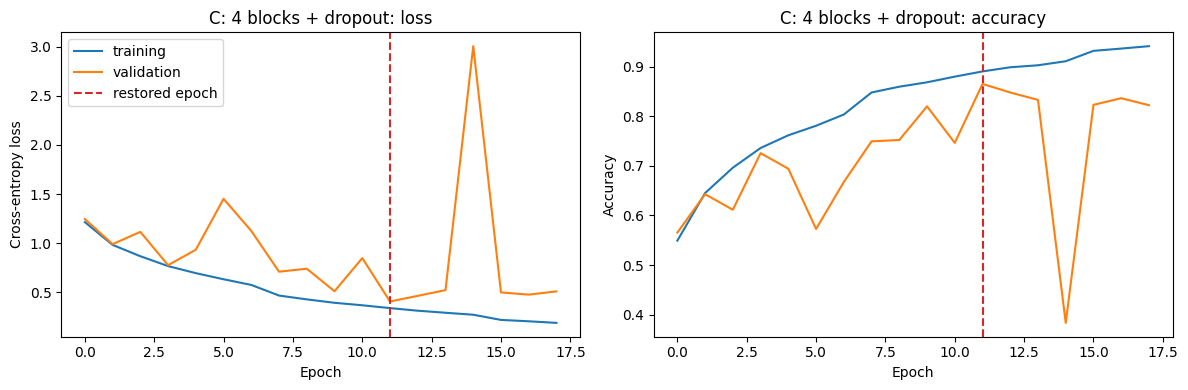

In [9]:
h = runs[selected]["history"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
for ax, key, label in [(a1, "loss", "Cross-entropy loss"), (a2, "accuracy", "Accuracy")]:
    ax.plot(h[key], label="training")
    ax.plot(h[f"val_{key}"], label="validation")
    ax.axvline(int(np.argmin(h["val_loss"])), color="tab:red", ls="--", label="restored epoch")
    ax.set(xlabel="Epoch", ylabel=label, title=f"{selected}: {key}")
a1.legend()
fig.tight_layout()
fig.savefig(FIGURES / "spec_cnn_curves.png", dpi=200)

## 4. Test (once) and comparison with the summary baseline (H3)

,accuracy,macro_f1,mcc,macro_auc_ovr
model,,,,
cnn,0.8520,0.8516,0.824,0.9844
logreg_summary,0.7473,0.7454,0.697,0.9403
zeror,0.1668,0.0477,0.000,0.5000


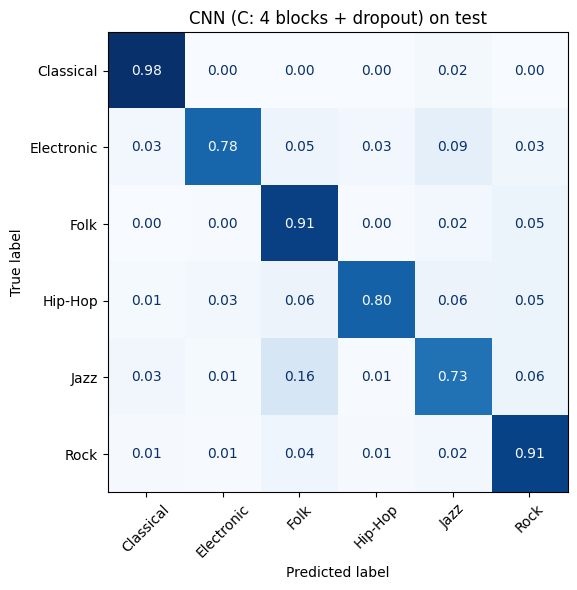

In [10]:
best = runs[selected]
proba = best["model"].predict(Xte, batch_size=64, verbose=0)
y_true, y_pred = le.classes_[yte], le.classes_[proba.argmax(1)]
metrics, per_class = evaluate(y_true, y_pred, proba, labels=le.classes_)
cfg = archs[selected]
save_result("cnn", "spec", metrics, params={"architecture": selected, "filters": list(cfg["filters"]),
            "dropout": cfg.get("dropout", 0.0), "epochs": best["epochs"], "n_params": best["params"]})
# Test predictions kept for the error analysis in notebook 07 (ids and labels only, no spectrogram data).
pd.DataFrame({"id": test_part["id"].to_numpy(), "true": y_true, "pred": y_pred,
              "confidence": proba.max(1).round(4)}).to_csv(RESULTS / "spec" / "cnn_test_predictions.csv", index=False)
fig = plot_confusion(y_true, y_pred, labels=le.classes_, title=f"CNN ({selected}) on test")
fig.savefig(FIGURES / "spec_cnn_confusion.png", dpi=200)
results_table("spec")[["accuracy", "macro_f1", "mcc", "macro_auc_ovr"]]

In [11]:
per_class.sort_values("recall_tpr")

,precision,recall_tpr,fpr,f1,support
Jazz,0.7800,0.7333,0.0414,0.7559,435
Electronic,0.9363,0.7788,0.0106,0.8503,434
Hip-Hop,0.9454,0.7954,0.0092,0.8639,435
Rock,0.8178,0.9101,0.0405,0.8615,434
Folk,0.7524,0.9149,0.0603,0.8257,435
Classical,0.9261,0.9793,0.0156,0.9520,435


H3 predicts the CNN beats logistic regression on the per-band summary features, because it keeps local time-frequency patterns that the summary averages away. Compare the `cnn` and `logreg_summary` rows above.

## 5. Misclassified test clips

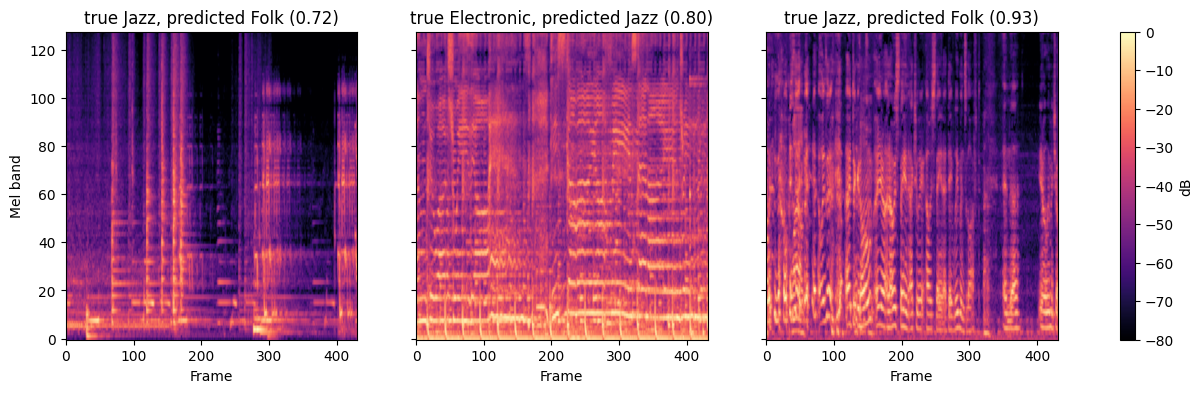

In [12]:
wrong = np.random.default_rng(SEED).choice(np.flatnonzero(y_true != y_pred), 3, replace=False)
raw = load_spectrograms(test_part["path"].iloc[wrong])  # reload in dB for display
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, i, s in zip(axes, wrong, raw):
    im = ax.imshow(s, origin="lower", aspect="auto", cmap="magma", vmin=-80, vmax=0)
    ax.set(title=f"true {y_true[i]}, predicted {y_pred[i]} ({proba[i].max():.2f})", xlabel="Frame")
axes[0].set_ylabel("Mel band")
fig.colorbar(im, ax=axes, label="dB")
fig.savefig(FIGURES / "spec_cnn_misclassified.png", dpi=200)

In [13]:
# On Kaggle: bundle this run's figures and results for download (Output tab: cnn_outputs.zip). Extract it into the repo root.
if Path("/kaggle/working").exists():
    import zipfile
    with zipfile.ZipFile("/kaggle/working/cnn_outputs.zip", "w") as z:
        for f in [*FIGURES.glob("spec_cnn_*.png"), *(RESULTS / "spec").glob("cnn*")]:
            z.write(f, f.relative_to(FIGURES.parent))
    print(z.namelist())

['figures/spec_cnn_curves.png', 'figures/spec_cnn_misclassified.png', 'figures/spec_cnn_confusion.png', 'results/spec/cnn.json', 'results/spec/cnn_test_predictions.csv']


## Findings

- **Hardware:** trained on a Kaggle T4 GPU. All three architectures took about 21 minutes in total (11-16 s per epoch).
- **Architectures (validation macro-F1):** A, 2 blocks (19,494 parameters): 0.725. B, 3 blocks with dropout (94,118): 0.807. C, 4 blocks with dropout (390,822): 0.866. Each extra block helped, so C was chosen. A and B used all 40 epochs and were still improving, so longer training might narrow the gap.
- **Training curves (C):** training accuracy kept rising to 0.94, but validation accuracy peaked at 0.865 at epoch 12, so the network started to overfit after that. Early stopping kept the epoch-12 weights. One unstable epoch (15) pushed validation loss to 3.0 before the learning rate was halved.
- **Test result and H3:** the CNN scored 0.852 macro-F1 (MCC 0.824, AUC 0.984), against 0.745 for logistic regression on summary features. That is 273 more of the 2,608 test clips right. H3 is supported: keeping the time-frequency patterns helps. Possible song leakage affects both models, so the comparison stays fair.
- **Per-genre results:** Classical is easiest (recall 0.98), then Folk and Rock (0.91). Jazz is still hardest (0.73) but up from 0.58 with the baseline. The largest error is Jazz predicted as Folk (16%).
- **Wrong predictions:** two of the three examples shown are Jazz predicted as Folk, one with 0.93 confidence. These clips share Folk's acoustic, harmonic texture, so the errors come from genuinely similar music.
